<a href="https://colab.research.google.com/github/Ashwini9713/fundamentals-of-ML/blob/main/exp_18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Accuracy: 0.8667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.88      0.70      0.78        10
   virginica       0.75      0.90      0.82        10

    accuracy                           0.87        30
   macro avg       0.88      0.87      0.87        30
weighted avg       0.88      0.87      0.87        30



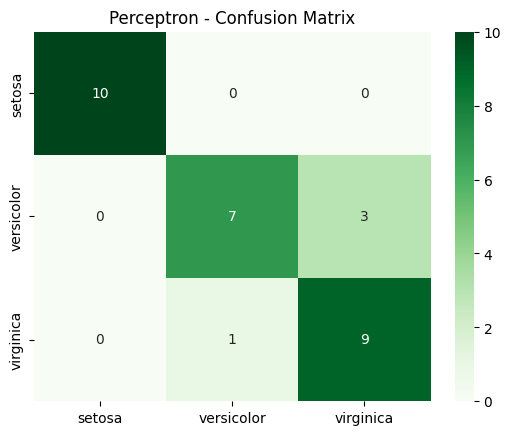

Scratch perceptron accuracy: 1.0


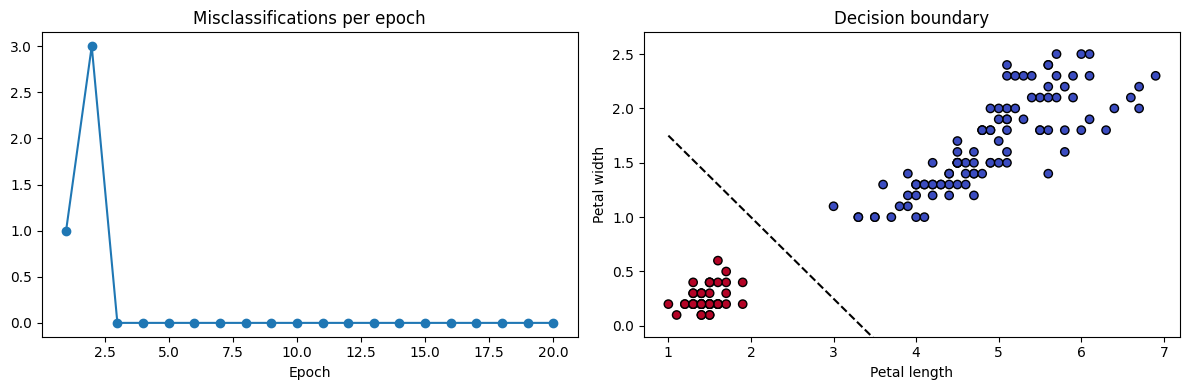

In [3]:
from sklearn.datasets import load_iris
from sklearn.linear_model import Perceptron

iris = load_iris()
X, y = iris.data, iris.target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
sc = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = sc.transform(X_tr), sc.transform(X_te)

per = Perceptron(max_iter=1000, eta0=0.1, random_state=42).fit(X_tr_s, y_tr)
pred = per.predict(X_te_s)
print('Accuracy:', round(accuracy_score(y_te, pred), 4))
print(classification_report(y_te, pred, target_names=iris.target_names))
sns.heatmap(confusion_matrix(y_te, pred), annot=True, fmt='d', cmap='Greens',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title('Perceptron - Confusion Matrix'); plt.show()

# ---- Perceptron from scratch (Setosa vs rest) ----
class SimplePerceptron:
    def __init__(self, lr=0.1, epochs=20): self.lr, self.epochs = lr, epochs
    def fit(self, X, y):
        self.w, self.b, self.errors = np.zeros(X.shape[1]), 0.0, []
        for _ in range(self.epochs):
            e = 0
            for xi, t in zip(X, y):
                upd = self.lr * (t - self.predict(xi))
                self.w += upd * xi; self.b += upd; e += int(upd != 0)
            self.errors.append(e)
        return self
    def predict(self, X): return np.where(np.dot(X, self.w) + self.b >= 0, 1, 0)

yb = (y == 0).astype(int)
sp = SimplePerceptron().fit(X[:, [2, 3]], yb)       # petal length, petal width
print('Scratch perceptron accuracy:', accuracy_score(yb, sp.predict(X[:, [2, 3]])))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, 21), sp.errors, marker='o'); ax[0].set(title='Misclassifications per epoch', xlabel='Epoch')
ax[1].scatter(X[:, 2], X[:, 3], c=yb, cmap='coolwarm', edgecolor='k')
xs = np.linspace(X[:, 2].min(), X[:, 2].max(), 50)
ax[1].plot(xs, -(sp.w[0]*xs + sp.b)/sp.w[1], 'k--')
ax[1].set(title='Decision boundary', xlabel='Petal length', ylabel='Petal width')
ax[1].set_ylim(X[:, 3].min()-.2, X[:, 3].max()+.2)
plt.tight_layout(); plt.show()

In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             mean_squared_error, r2_score, mean_absolute_error)
np.random.seed(42)